In [340]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [341]:
import numpy as np
from mytools.halo_new import get_coord, get_mask_sector, get_mask_square, generate_local_noise_weights
from mytools.plot import plot_heatmap, plot_stack_fit_res, plot_axlines, plot_hist, plot_line_diff, make_figure, set_ticks, plt
from crafts_stack.halo_fitting import build_model, halofit, cov_to_err_map
from astropy.stats import sigma_clip

<Axes: title={'center': 'Test'}, xlabel='X', ylabel='Y'>

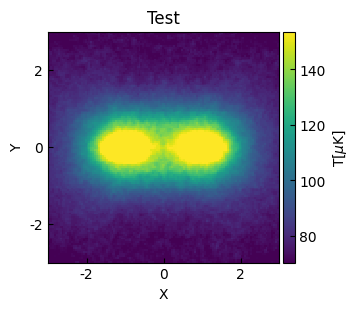

In [342]:
# data = np.load('../data/tng_pairstack_result_cube.npz', 'r')['data']
data = np.load('../data/tng_pairstack_result_hpmap.npz', 'r')['data']
# data = np.load('../data/crafts_pairstack_result_airpls.npz', 'r')['data']

# data = sigma_clip(data, sigma=10, masked=True)
plot_heatmap(data, title='Test')

In [ ]:
coord = get_coord()

name = 'nfw'
# bg_name = 'poly'
bg_name = 'const'

tolenrance = 0.1

bounds = {
    'amplitude_0': (0, 200),
    'amplitude_1': (0, 200),
    # 'x_mean_0': (-1 - tolenrance, -1 + tolenrance),
    # 'x_mean_1': (1 - tolenrance, 1 + tolenrance),
    # 'y_mean_0': (0 - tolenrance, 0 + tolenrance),
    # 'y_mean_1': (0 - tolenrance, 0 + tolenrance),
    'ellipticity_0': (0, 0.4),
    'ellipticity_1': (0, 0.4),
    # 'theta_0': (0, 10),
    # 'theta_1': (0, 10),
    # 'r_s_0': (0.1, 10),
    # 'r_s_1': (0.1, 10),
}

constraints = {
    # "fixed": ['ellipticity_0', 'ellipticity_1'],
    "fixed": ['x_mean_0', 'y_mean_0', 'x_mean_1', 'y_mean_1'], # fix the center of the two NFW profiles
    "tied": [
        # ("amplitude_1", "amplitude_0"),  # amplitude_1 = amplitude_0
        ("ellipticity_1", "ellipticity_0"),
        # ("r_s_1", "r_s_2"),
        # ('c0_0_2', 'c0_0_3'),  
        # ('c1_0_2', 'c1_0_3'),  
        # ('c2_0_2', 'c2_0_3'), 
        # ('c0_1_2', 'c0_1_3'),
        # ('c0_2_2', 'c0_2_3'),
        # ('c1_1_2', 'c1_1_3'),
    ]
}

init_bg = {
    # "degree": 1
}

model = build_model(name, bg_name, init_bg=init_bg, bounds=bounds, constraints=constraints)
print(model)

Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <Lorentz2D(amplitude=50., x_mean=-1., y_mean=0., fwhm=1., ellipticity=0., theta=0.)>

    [1]: <Lorentz2D(amplitude=50., x_mean=1., y_mean=0., fwhm=1., ellipticity=0., theta=0.)>

    [2]: <Const2D(amplitude=1.)>
Parameters:
    amplitude_0 x_mean_0 y_mean_0 fwhm_0 ... ellipticity_1 theta_1 amplitude_2
    ----------- -------- -------- ------ ... ------------- ------- -----------
           50.0     -1.0      0.0    1.0 ...           0.0     0.0         1.0


<Axes: title={'center': 'Weight'}, xlabel='X', ylabel='Y'>

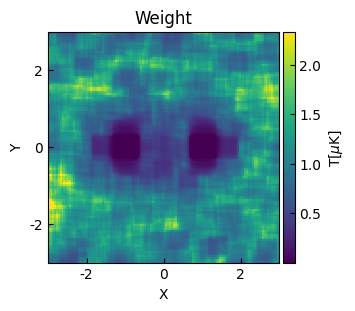

In [413]:
weights = generate_local_noise_weights(data, local_variance_scale=10, smoothing_scale=3)
# weights = read_h5(weight_path, 'crafts_122k/weight')
plot_heatmap(weights, title='Weight', q=0.1)

# without mask

In [438]:
data_list, fit_model, fit_info = halofit(coord, data, model=model, print_model=True, weights=weights)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <Lorentz2D(amplitude=131.68208495, x_mean=-1., y_mean=0., fwhm=1.45230555, ellipticity=0.28540613, theta=0.00354799)>

    [1]: <Lorentz2D(amplitude=128.49414935, x_mean=1., y_mean=0., fwhm=1.4439472, ellipticity=0.28540613, theta=-0.01443277)>

    [2]: <Const2D(amplitude=64.29403669)>
Parameters:
      amplitude_0    x_mean_0 y_mean_0 ...       theta_1           amplitude_2   
    ---------------- -------- -------- ... -------------------- -----------------
    131.682084954423     -1.0      0.0 ... -0.01443277377048601 64.29403669439019

Goodness of fit:
Chi-squared: 1105508.713
Reduced chi-squared: 76.841
RMS residual: 8.762



<Axes: title={'center': 'Poly'}, xlabel='X', ylabel='Y'>

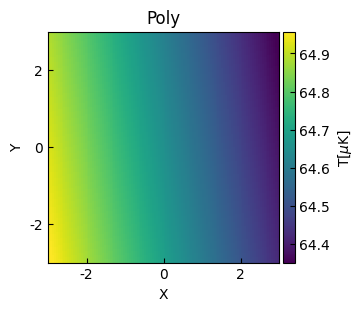

In [439]:
from astropy.modeling.models import Polynomial2D
m_poly = Polynomial2D(31, c0_0=64.65436775, c1_0=-0.27029577, c0_1=-0.03973656, x_domain=(-3, 3), y_domain=(-3, 3))
plot_heatmap(m_poly(*coord), title='Poly', q=0.1)

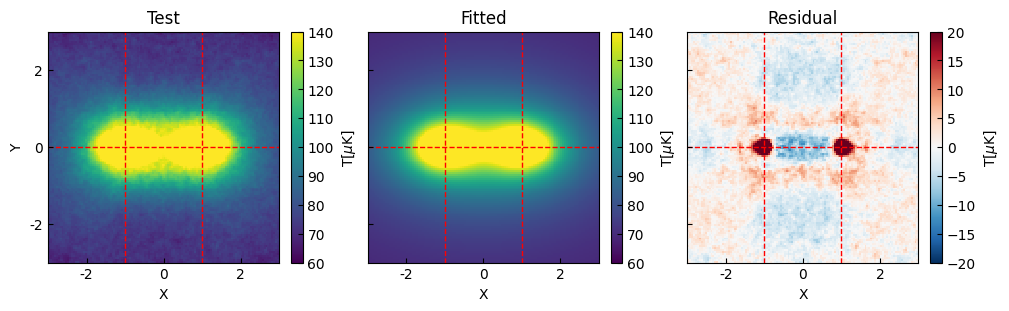

In [440]:
title = ['Test', 'Fitted', 'Residual']
# axes =  plot_stack_fit_res(data_list, title=title)
axes =  plot_stack_fit_res(data_list, title=title, vmax=[140,140, 20], vmin=[60, 60, -20])
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

<Axes: title={'center': 'Error Map'}, xlabel='X', ylabel='Y'>

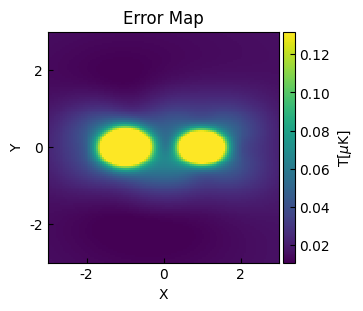

In [441]:
error_map = cov_to_err_map(fit_model, fit_info, *coord)
plot_heatmap(error_map, title='Error Map') 

# with mask sector 

<Axes: title={'center': 'Mask'}, xlabel='X', ylabel='Y'>

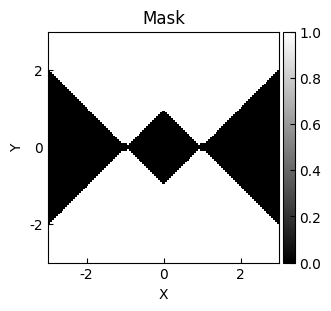

In [465]:
# mask_sector = get_mask_sector(coord=coord)
mask_sector = get_mask_sector(rlim=[0.1,5], coord=coord)
# mask_sector = get_mask_sector(thetalim=[-np.pi/3, np.pi/3], coord=coord)
plot_heatmap(mask_sector, title='Mask', cmap='gray', cbar_label='')

In [466]:
data_list_sector, fit_model, fit_info = halofit(coord, data, model=model, mask=mask_sector, print_model=True, weights=weights[mask_sector])


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <Lorentz2D(amplitude=168.0559419, x_mean=-1., y_mean=0., fwhm=1.44738503, ellipticity=0.4, theta=-37.71149748)>

    [1]: <Lorentz2D(amplitude=168.59986646, x_mean=1., y_mean=0., fwhm=1.40295884, ellipticity=0.4, theta=25.12445172)>

    [2]: <Const2D(amplitude=64.50955948)>
Parameters:
       amplitude_0     x_mean_0 y_mean_0 ...      theta_1          amplitude_2   
    ------------------ -------- -------- ... ------------------ -----------------
    168.05594190012843     -1.0      0.0 ... 25.124451723347885 64.50955948401463

Goodness of fit:
Chi-squared: 134695.451
Reduced chi-squared: 13.033
RMS residual: 3.608



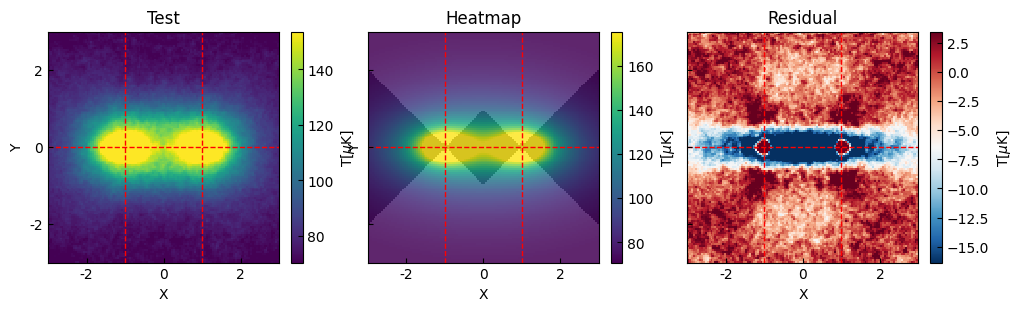

In [ ]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list_sector, title=title, fit_mask=mask_sector)
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

<Axes: title={'center': 'Error Map'}, xlabel='X', ylabel='Y'>

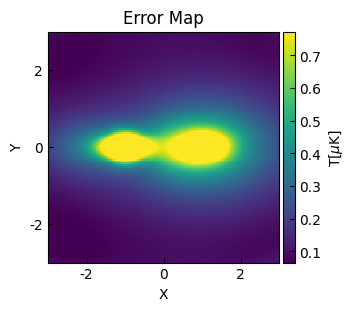

In [352]:
error_map = cov_to_err_map(fit_model, fit_info, *coord)
plot_heatmap(error_map, title='Error Map') 

# with mask square

<Axes: title={'center': 'Mask'}, xlabel='X', ylabel='Y'>

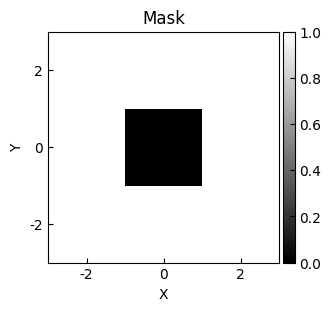

In [442]:
# mask_sq = ~get_mask_square(coord=coord)
mask_sq = ~get_mask_square(coord=coord, xlim=[-1, 1], ylim=[-1, 1])

plot_heatmap(mask_sq, title='Mask', cmap='gray', cbar_label='')

In [443]:
data_list_square, fit_model, fit_info = halofit(coord, data, model=model, mask=mask_sq, print_model=True, weights=weights[mask_sq])
# data_list_square, fit_model, fit_info = halofit(coord, data, model=model, mask=mask_sq, print_model=True)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <Lorentz2D(amplitude=160.20058095, x_mean=-1., y_mean=0., fwhm=1.28416645, ellipticity=0.28874255, theta=0.00504868)>

    [1]: <Lorentz2D(amplitude=180.46949372, x_mean=1., y_mean=0., fwhm=1.16844335, ellipticity=0.28874255, theta=-0.01227746)>

    [2]: <Const2D(amplitude=64.94357125)>
Parameters:
       amplitude_0     x_mean_0 y_mean_0 ...        theta_1           amplitude_2   
    ------------------ -------- -------- ... --------------------- -----------------
    160.20058095131174     -1.0      0.0 ... -0.012277464228054327 64.94357125336748

Goodness of fit:
Chi-squared: 448387.880
Reduced chi-squared: 35.066
RMS residual: 5.919



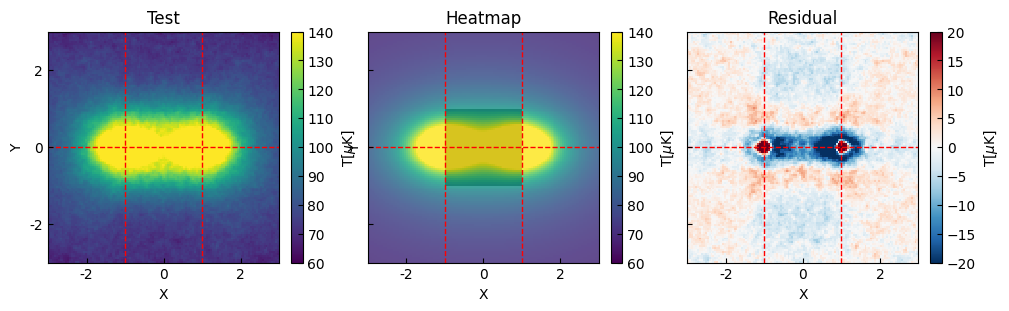

In [453]:
title = ['Test', 'Fitted', 'Residual']
# axes =  plot_stack_fit_res(data_list_square, title=title, fit_mask=mask_sq)
axes =  plot_stack_fit_res(data_list_square, title=title, fit_mask=mask_sq, vmax=[140,140, 20], vmin=[60, 60, -20])
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

<Axes: title={'center': 'Error Map'}, xlabel='X', ylabel='Y'>

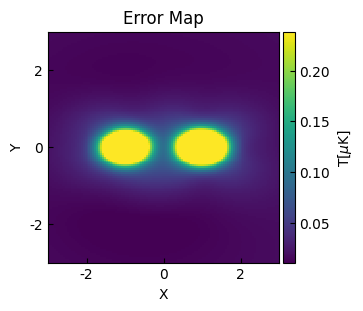

In [445]:
error_map = cov_to_err_map(fit_model, fit_info, *coord)
plot_heatmap(error_map, title='Error Map') 

# compare

(-100.0, 100.0)

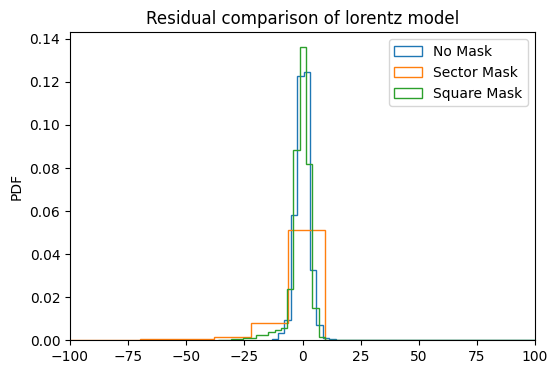

In [446]:
res_list = [data_list[-1].flatten(), data_list_sector[-1].flatten(), data_list_square[-1].flatten()]
labels = ['No Mask', 'Sector Mask', 'Square Mask']
title = 'Residual comparison of %s model' %(name)
ax = plot_hist(res_list, label=labels, bins=100, title=title)
ax.set_xlim(-100, 100)

# profiles

In [447]:
stack_fit_res = data_list
# stack_fit_res = data_list_sector
# stack_fit_res = data_list_square

In [454]:
get_yprofile = lambda dlist, ind: [x[ind,:] for x in dlist]
get_xprofile = lambda dlist, ind: [x[:,ind] for x in dlist]

lines_list = [
    get_yprofile(stack_fit_res[:2], 60),
    get_xprofile(stack_fit_res[:2], 40),
    get_xprofile(stack_fit_res[:2], 80),
]
title_list = ['Y=0', 'X=-1', 'X=1']

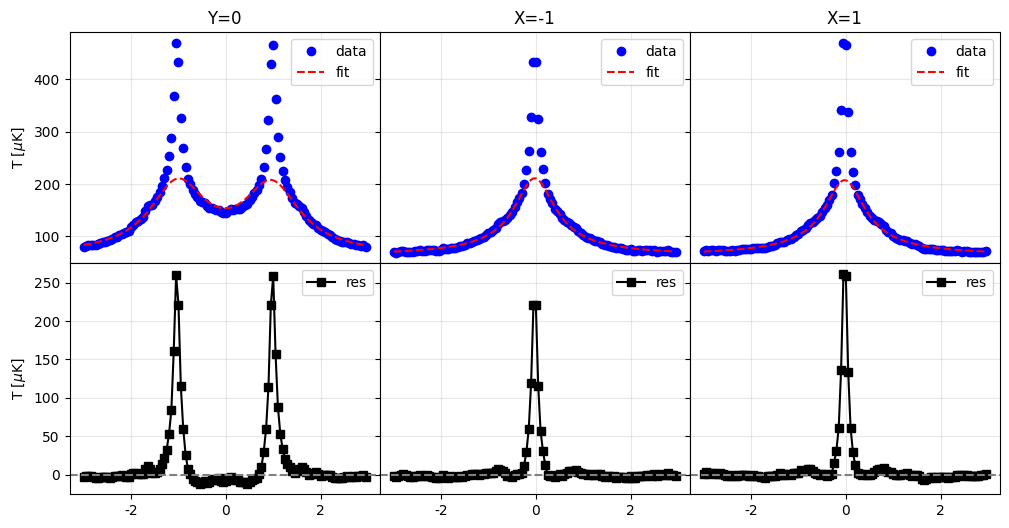

In [455]:
fig, axes = make_figure(2,3, figsize=(12,6), wspace=0., hspace=0.,aspect=None,sharex=True, sharey='row')

for i, lines in enumerate(lines_list):
    _axes = [axes[0,i], axes[1,i]]

    plot_line_diff(*lines, title=title_list[i], axes=_axes, labels=['data', 'fit', 'res'])

axes[0,0].set_ylabel(r'T [$\mu$K]')
axes[1,0].set_ylabel(r'T [$\mu$K]')
set_ticks(axes[1,0], share=False)

# estimate signal level

In [450]:
from mytools.estimate import get_signal_level
from mytools.plot import plot_profile_2c, plot_hist, make_figure
from mytools.data import read_h5

<Axes: title={'center': 'Weight'}, xlabel='X', ylabel='Y'>

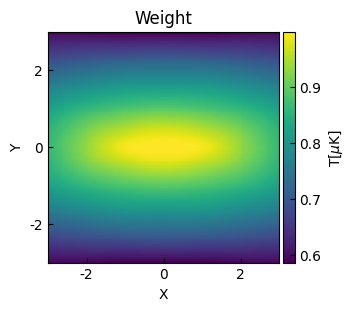

In [456]:
weight_path= '../data/pixcount_xsize3000_nfs10.h5'
pix_weights = read_h5(weight_path, 'tng_120k/weight')
# weights = read_h5(weight_path, 'crafts_122k/weight')
plot_heatmap(pix_weights, title='Weight', q=0.1)

Parameter names:
('amplitude_0', 'mean_0', 'stddev_0', 'amplitude_1')
Gauss fit parameters: [np.float64(8.040319721841383), np.float64(0.0), np.float64(0.01), np.float64(-2.034439841454993)]
Gauss fit covariance: 
[[ 5.57286978e+22 -1.09057863e+19  4.22865695e+09]
 [-1.09057863e+19  2.13419979e+15 -8.27523896e+05]
 [ 4.22865695e+09 -8.27523896e+05  1.28413753e-02]]
0 points clipped during sigma clipping.

Goodness of fit:
Chi-squared: 1128.268
Reduced chi-squared: 9.643
RMS residual: 3.066

width: 0.01
width_pix: 0


/home/dyliu/miniconda3/envs/astro/lib/python3.13/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/dyliu/miniconda3/envs/astro/lib/python3.13/site-packages/numpy/_core/_methods.py:136: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(


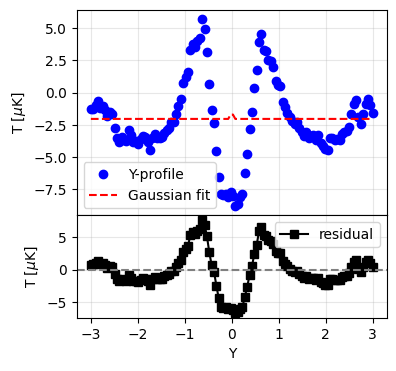

In [463]:
res = stack_fit_res[-1]
# bounds = (
#     [0, 0.1, -np.inf],
#     [np.inf, 0.7, np.inf],
# )
bounds = {
    "amplitude_0": (-np.inf, np.inf),  # amp > 0
    "stddev_0": (0.01, 0.75),  # sigma
}
lx, ly, clrb, params, cov = get_signal_level(res, weights=pix_weights, bounds=bounds, sigma_clip_sigma=3, show_fit=True);
# lx, ly, clrb, params, cov = get_signal_level(res, bounds=bounds, sigma_clip_sigma=5, weights=weight[:,50:70].mean(axis=1), show_fit=False);
# lx, ly, clrb, params, cov = get_signal_level(res);

array([<Axes: title={'center': 'Transverse-section profile'}, xlabel='Y', ylabel='$T$[$\\mu$K]'>,
       <Axes: title={'center': 'Lengthwise-section profile'}, xlabel='X'>],
      dtype=object)

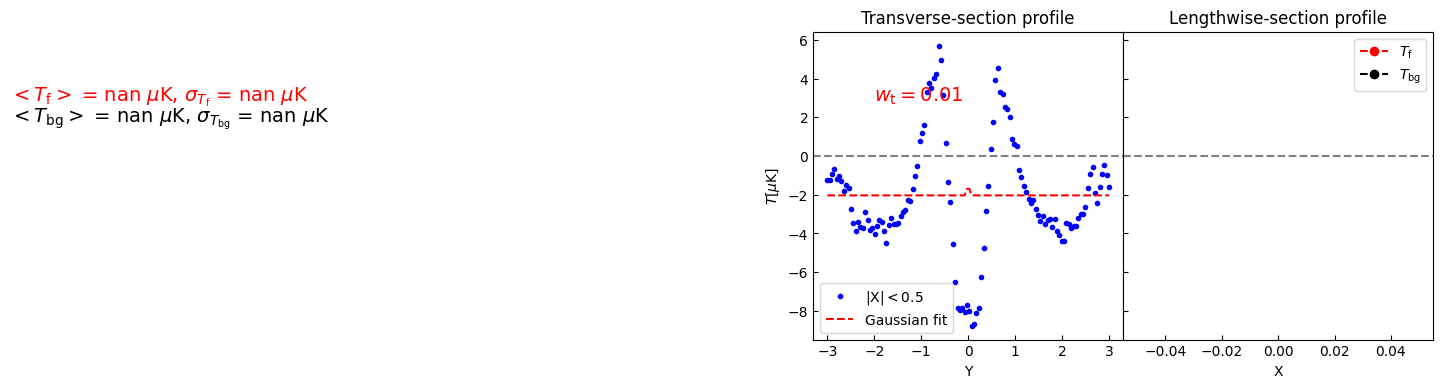

In [464]:
text_pos = [
    [-0.45, 0.5 * np.max(ly[0])], 
    [-0.45, -0.2* np.min(ly[0])], 
    [-2, 0.5 * np.max(ly[0])],
]
fig, axes = make_figure(1, 2, figsize=(8,4),wspace=0.,aspect=None,sharex=False)
plot_profile_2c(lx, ly, axes=axes, width=params[2], text_pos=text_pos)

<Axes: title={'center': 'Signal level'}, ylabel='PDF'>

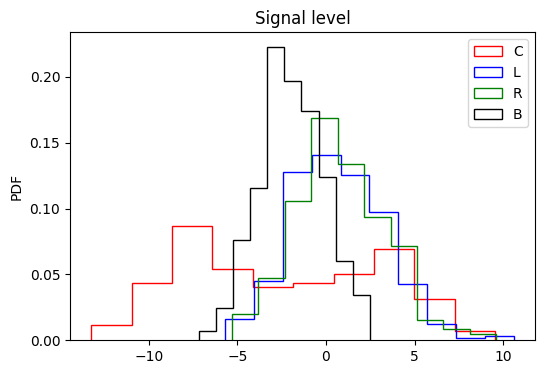

In [462]:
plot_hist(clrb, label=['C','L','R','B'], color=['r', 'b','g','k'], title='Signal level')